In [ ]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

In [2]:
#POI

In [2]:
from pathlib import Path

print(Path.cwd())

C:\Users\rg25503\OneDrive - University of Bristol\Dissertation\Pycharm_Projects


In [4]:
poi_1_path = Path("Data/POI/South_West_England/poi_6426709/poi_6426709.gpkg")
df_poi1 = gpd.read_file(poi_1_path, engine="pyogrio")
df_poi1.head()

,ref_no,name,pointx_class,groupname,categoryname,classname,feature_easting,feature_northing,pos_accuracy,uprn,...,postcode,admin_boundary,telephone_number,url,brand,qualifier_type,qualifier_data,provenance,supply_date,geometry
0,165160100,Wood of Bournemouth Ltd,09490695,Retail,Motoring,New Vehicles,406238.0,94107.0,1,1.000109e+10,...,BH12 5WB,"Bournemouth, Christchurch and Poole",01202535535,NaN,NaN,NaN,NaN,118 Information,2026-03-01,POINT (406238 94107)
1,166808979,Cupra Southampton,09490695,Retail,Motoring,New Vehicles,438119.0,113186.0,1,1.000627e+11,...,SO15 0LP,City of Southampton,02380733733,www.snows.co.uk,Snows Motor Group,NaN,NaN,118 Information,2026-03-01,POINT (438119 113186)
2,166808983,Snows Peugeot Newbury,09490695,Retail,Motoring,New Vehicles,447738.0,165122.0,1,1.000920e+10,...,RG14 7HT,West Berkshire,01635572900,www.snows.co.uk,Peugeot,NaN,NaN,118 Information,2026-03-01,POINT (447738 165122)
3,169654157,Garrett Dorset,09490695,Retail,Motoring,New Vehicles,406086.0,91299.0,1,1.000408e+11,...,BH13 6DZ,"Bournemouth, Christchurch and Poole",01202287828,NaN,NaN,NaN,NaN,118 Information,2026-03-01,POINT (406086 91299)
4,169654309,Found by Fox,09490695,Retail,Motoring,New Vehicles,402572.0,154623.0,1,1.001210e+11,...,SN10 4PB,Wiltshire,08452412417,NaN,NaN,NaN,NaN,118 Information,2026-03-01,POINT (402572 154623)


In [5]:
df_poi1.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 205017 entries, 0 to 205016
Data columns (total 29 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   ref_no             205017 non-null  int64         
 1   name               205017 non-null  str           
 2   pointx_class       205017 non-null  str           
 3   groupname          205017 non-null  str           
 4   categoryname       205017 non-null  str           
 5   classname          205017 non-null  str           
 6   feature_easting    205017 non-null  float64       
 7   feature_northing   205017 non-null  float64       
 8   pos_accuracy       205017 non-null  int64         
 9   uprn               100918 non-null  float64       
 10  topo_toid          205017 non-null  str           
 11  topo_toid_version  205017 non-null  int64         
 12  usrn               205017 non-null  str           
 13  usrn_mi            205017 non-null  

In [21]:
from mpl_toolkits.axes_grid1 import make_axes_locatable

C:\Users\rg25503\AppData\Local\Temp\ipykernel_22500\344363305.py:2: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title="Group Name")


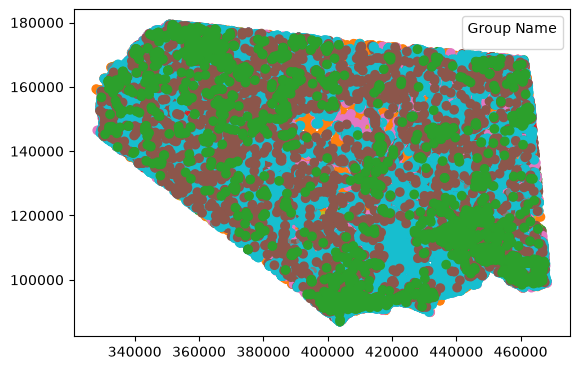

In [4]:
ax = df_poi1.plot(column="groupname", legend=True)
ax.legend(title="Group Name")

In [44]:
#df_poi1 = df_poi1.to_crs(epsg=4326)

#m = df_poi1.explore(
#    tiles = "OpenStreetMap",
#    marker_kwds = {"radius": 0.01},
#    tooltips =True
#)

#m.save("poi1_map.html")

In [ ]:
# Merge POI geopackages

In [3]:
from pathlib import Path
import geopandas as gpd
import pandas as pd

poi_dir = Path("Data/POI/South_West_England")

poi_files = sorted(poi_dir.rglob("*.gpkg"))

print(f"Found {len(poi_files)} GeoPackage files")

Found 4 GeoPackage files


In [4]:
# Check CRS of each POI files

for file in poi_files:
    gdf = gpd.read_file(file, engine="pyogrio")
    print(file.name, gdf.crs)

poi_6426697.gpkg EPSG:27700
poi_6426700.gpkg EPSG:27700
poi_6426709.gpkg EPSG:27700
poi_6426711.gpkg EPSG:27700


In [5]:
# Combine all POIs

poi_merge = []

for file in poi_files:
    gdf = gpd.read_file(file, engine="pyogrio")

    # Keep the source file information
    gdf["source_file"] = file.name
    gdf["source_folder"] = file.parent.name

    poi_merge.append(gdf)

poi_all = gpd.GeoDataFrame(
    pd.concat(poi_merge, ignore_index=True),
    geometry="geometry",
    crs=poi_merge[0].crs
)

print(poi_all.shape)
poi_all.head()


(569463, 31)


,ref_no,name,pointx_class,groupname,categoryname,classname,feature_easting,feature_northing,pos_accuracy,uprn,...,telephone_number,url,brand,qualifier_type,qualifier_data,provenance,supply_date,geometry,source_file,source_folder
0,166806215,Carrs Volkswagen Van Centre Indian Queens,09490695,Retail,Motoring,New Vehicles,192388.0,59304.0,1,1.003463e+10,...,01726259107,www.volkswagen.co.uk,Volkswagen,NaN,NaN,118 Information,2026-03-01,POINT (192388 59304),poi_6426697.gpkg,poi_6426697
1,166806217,Carrs Select Scorrier,09490695,Retail,Motoring,New Vehicles,172473.0,44630.0,1,NaN,...,01872398599,NaN,Helston Garages Group,NaN,NaN,118 Information,2026-03-01,POINT (172473 44630),poi_6426697.gpkg,poi_6426697
2,166806224,Vertu Volvo Truro,09490695,Retail,Motoring,New Vehicles,177715.0,45002.0,1,1.000410e+11,...,01872461413,www.vertumotors.com,Volvo,NaN,NaN,118 Information,2026-03-01,POINT (177715 45002),poi_6426697.gpkg,poi_6426697
3,166806225,Carrs Land Rover,09490695,Retail,Motoring,New Vehicles,172552.0,44706.0,1,1.000121e+10,...,01872398387,NaN,Land Rover,NaN,NaN,118 Information,2026-03-01,POINT (172552 44706),poi_6426697.gpkg,poi_6426697
4,181524408,Exeter Van Store,09490695,Retail,Motoring,New Vehicles,291945.6,90995.5,1,1.001304e+10,...,01392424150,www.hendycarstore.co.uk,Hendy Group,NaN,NaN,118 Information,2026-03-01,POINT (291945.6 90995.5),poi_6426697.gpkg,poi_6426697


In [8]:
# Check Duplicates

In [6]:
print("Duplicate ref_no:",
      poi_all["ref_no"].duplicated().sum())

Duplicate ref_no: 41061


In [7]:
poi_all[
    poi_all.duplicated(subset=["ref_no"], keep=False)
].sort_values("ref_no")

,ref_no,name,pointx_class,groupname,categoryname,classname,feature_easting,feature_northing,pos_accuracy,uprn,...,telephone_number,url,brand,qualifier_type,qualifier_data,provenance,supply_date,geometry,source_file,source_folder
40062,14356050,Addlepool,03190259,Attractions,Landscape Features,Trigonometric Points,298987.2,88163.7,1,NaN,...,NaN,NaN,NaN,NaN,NaN,Ordnance Survey,2026-03-01,POINT (298987.2 88163.7),poi_6426697.gpkg,poi_6426697
149529,14356050,Addlepool,03190259,Attractions,Landscape Features,Trigonometric Points,298987.2,88163.7,1,NaN,...,NaN,NaN,NaN,NaN,NaN,Ordnance Survey,2026-03-01,POINT (298987.2 88163.7),poi_6426700.gpkg,poi_6426700
149522,14356191,Aylesbeare Common,03190259,Attractions,Landscape Features,Trigonometric Points,305504.7,90012.5,1,NaN,...,NaN,NaN,NaN,NaN,NaN,Ordnance Survey,2026-03-01,POINT (305504.7 90012.5),poi_6426700.gpkg,poi_6426700
40056,14356191,Aylesbeare Common,03190259,Attractions,Landscape Features,Trigonometric Points,305504.7,90012.5,1,NaN,...,NaN,NaN,NaN,NaN,NaN,Ordnance Survey,2026-03-01,POINT (305504.7 90012.5),poi_6426697.gpkg,poi_6426697
462866,14356718,Blandys Hill,03190259,Attractions,Landscape Features,Trigonometric Points,438766.1,165954.1,1,NaN,...,NaN,NaN,NaN,NaN,NaN,Ordnance Survey,2026-03-01,POINT (438766.1 165954.1),poi_6426711.gpkg,poi_6426711
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9269,184391262,Buddleigh Mini Supermarket,02090811,Commercial Services,Legal and Financial,Paypoint Locations,306345.0,81887.0,1,1.000410e+11,...,NaN,www.paypoint.co.uk,PayPoint,NaN,NaN,PayPoint,2026-03-01,POINT (306345 81887),poi_6426697.gpkg,poi_6426697
9304,184391280,Asda Express,02090811,Commercial Services,Legal and Financial,Paypoint Locations,284028.0,99553.0,1,1.000411e+11,...,NaN,www.paypoint.co.uk,PayPoint,NaN,NaN,PayPoint,2026-03-01,POINT (284028 99553),poi_6426697.gpkg,poi_6426697
127716,184391280,Asda Express,02090811,Commercial Services,Legal and Financial,Paypoint Locations,284028.0,99553.0,1,1.000411e+11,...,NaN,www.paypoint.co.uk,PayPoint,NaN,NaN,PayPoint,2026-03-01,POINT (284028 99553),poi_6426700.gpkg,poi_6426700
191952,184396979,Sidwell Street Walk-in Centre,05280365,Education and Health,Health Practitioners and Establishments,Clinics and Health Centres,292448.0,92998.0,1,1.001304e+10,...,01392276892,NaN,NaN,NaN,NaN,HSJ Information Limited,2026-03-01,POINT (292448 92998),poi_6426700.gpkg,poi_6426700


In [ ]:
# Drop Duplicates

In [8]:
poi_all_clean = poi_all.drop_duplicates(subset=["ref_no"],
    keep="first"
).reset_index(drop=True)

In [9]:
poi_all_clean

,ref_no,name,pointx_class,groupname,categoryname,classname,feature_easting,feature_northing,pos_accuracy,uprn,...,telephone_number,url,brand,qualifier_type,qualifier_data,provenance,supply_date,geometry,source_file,source_folder
0,166806215,Carrs Volkswagen Van Centre Indian Queens,09490695,Retail,Motoring,New Vehicles,192388.0,59304.0,1,1.003463e+10,...,01726259107,www.volkswagen.co.uk,Volkswagen,NaN,NaN,118 Information,2026-03-01,POINT (192388 59304),poi_6426697.gpkg,poi_6426697
1,166806217,Carrs Select Scorrier,09490695,Retail,Motoring,New Vehicles,172473.0,44630.0,1,NaN,...,01872398599,NaN,Helston Garages Group,NaN,NaN,118 Information,2026-03-01,POINT (172473 44630),poi_6426697.gpkg,poi_6426697
2,166806224,Vertu Volvo Truro,09490695,Retail,Motoring,New Vehicles,177715.0,45002.0,1,1.000410e+11,...,01872461413,www.vertumotors.com,Volvo,NaN,NaN,118 Information,2026-03-01,POINT (177715 45002),poi_6426697.gpkg,poi_6426697
3,166806225,Carrs Land Rover,09490695,Retail,Motoring,New Vehicles,172552.0,44706.0,1,1.000121e+10,...,01872398387,NaN,Land Rover,NaN,NaN,118 Information,2026-03-01,POINT (172552 44706),poi_6426697.gpkg,poi_6426697
4,181524408,Exeter Van Store,09490695,Retail,Motoring,New Vehicles,291945.6,90995.5,1,1.001304e+10,...,01392424150,www.hendycarstore.co.uk,Hendy Group,NaN,NaN,118 Information,2026-03-01,POINT (291945.6 90995.5),poi_6426697.gpkg,poi_6426697
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
528397,64371470,Margaret Reid Display Solutions,02070101,Commercial Services,Contract Services,Display and Window Dressers,384301.0,201139.0,1,1.001214e+11,...,01453835555,NaN,NaN,NaN,NaN,118 Information,2026-03-01,POINT (384301 201139),poi_6426711.gpkg,poi_6426711
528398,104573666,Daktronics,02070101,Commercial Services,Contract Services,Display and Window Dressers,381424.0,212678.0,1,1.000731e+10,...,01454413606,NaN,NaN,NaN,NaN,118 Information,2026-03-01,POINT (381424 212678),poi_6426711.gpkg,poi_6426711
528399,161943034,Vod Visual,02070101,Commercial Services,Contract Services,Display and Window Dressers,411315.0,183056.3,1,1.009004e+10,...,07794229602,www.vod-visual.co.uk,NaN,NaN,NaN,118 Information,2026-03-01,POINT (411315 183056.3),poi_6426711.gpkg,poi_6426711
528400,161943125,The L E D Studio,02070101,Commercial Services,Contract Services,Display and Window Dressers,411315.0,183056.3,1,1.009004e+10,...,02039834490,www.theledstudio.co.uk,NaN,NaN,NaN,118 Information,2026-03-01,POINT (411315 183056.3),poi_6426711.gpkg,poi_6426711


In [10]:
poi_all_clean[
    poi_all_clean.duplicated(subset=["ref_no"], keep=False)
].sort_values("ref_no")

,ref_no,name,pointx_class,groupname,categoryname,classname,feature_easting,feature_northing,pos_accuracy,uprn,...,telephone_number,url,brand,qualifier_type,qualifier_data,provenance,supply_date,geometry,source_file,source_folder


In [ ]:
# Checking for empty geometries

In [16]:
poi_all_clean[poi_all_clean['geometry'].is_empty == True]

,ref_no,name,pointx_class,groupname,categoryname,classname,feature_easting,feature_northing,pos_accuracy,uprn,...,telephone_number,url,brand,qualifier_type,qualifier_data,provenance,supply_date,geometry,source_file,source_folder


In [ ]:
# Save merged crime data

In [61]:
poi_merged_path = Path("Data/POI/South_West_England/poi_merged.gpkg")

poi_all_clean.to_file(poi_merged_path, driver = "GPKG")

In [ ]:
# Crime data

In [12]:
crime_avon_12_path = Path("Data/Crime_data/South_West_England/db59bec88ae366adc60eeb95c32acbaae6937ddf/2025-12/2025-12-avon-and-somerset-street.csv")
df_crime_avon_12 = pd.read_csv(crime_avon_12_path, dtype="string", header=0)

In [38]:
df_crime_avon_12.head()

,Crime ID,Month,Reported by,Falls within,Longitude,Latitude,Location,LSOA code,LSOA name,Crime type,Last outcome category,Context
0,5402f92412e1adeab5f7a45eabbb474bf5bb3b79b23711...,2025-12,Avon and Somerset Constabulary,Avon and Somerset Constabulary,0.793839,51.210937,On or near Monks Walk,E01023986,Ashford 002B,Violence and sexual offences,Unable to prosecute suspect,<NA>
1,<NA>,2025-12,Avon and Somerset Constabulary,Avon and Somerset Constabulary,-2.492876,51.422716,On or near Trajectus Way,E01014399,Bath and North East Somerset 001A,Anti-social behaviour,<NA>,<NA>
2,<NA>,2025-12,Avon and Somerset Constabulary,Avon and Somerset Constabulary,-2.492876,51.422716,On or near Trajectus Way,E01014399,Bath and North East Somerset 001A,Anti-social behaviour,<NA>,<NA>
3,<NA>,2025-12,Avon and Somerset Constabulary,Avon and Somerset Constabulary,-2.492876,51.422716,On or near Trajectus Way,E01014399,Bath and North East Somerset 001A,Anti-social behaviour,<NA>,<NA>
4,<NA>,2025-12,Avon and Somerset Constabulary,Avon and Somerset Constabulary,-2.492876,51.422716,On or near Trajectus Way,E01014399,Bath and North East Somerset 001A,Anti-social behaviour,<NA>,<NA>


In [13]:
df_crime_avon_12.info()

<class 'pandas.DataFrame'>
RangeIndex: 15573 entries, 0 to 15572
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Crime ID               13721 non-null  string
 1   Month                  15573 non-null  string
 2   Reported by            15573 non-null  string
 3   Falls within           15573 non-null  string
 4   Longitude              14966 non-null  string
 5   Latitude               14966 non-null  string
 6   Location               15573 non-null  string
 7   LSOA code              14966 non-null  string
 8   LSOA name              14966 non-null  string
 9   Crime type             15573 non-null  string
 10  Last outcome category  13721 non-null  string
 11  Context                0 non-null      string
dtypes: string(12)
memory usage: 5.0 MB


In [ ]:
# Merge Crime Data

In [18]:
import pandas as pd

base_dir = Path(
    "Data/Crime_data/South_West_England/"
    "db59bec88ae366adc60eeb95c32acbaae6937ddf"
)

# Find every CSV inside all monthly subfolders
crime_files = sorted(base_dir.rglob("*.csv"))

print(f"Found {len(crime_files)} CSV files")

Found 61 CSV files


In [19]:
# Check if they have consistent columns

column_sets = {
    tuple(pd.read_csv(file, nrows=0).columns)
    for file in crime_files
}

print(f"Number of different column structures: {len(column_sets)}")

Number of different column structures: 2


In [20]:
# Merge all the files

crime_all = pd.concat(
    (
        pd.read_csv(
            file,
            low_memory=False
        ).assign(
            source_month=file.parent.name,
            source_file=file.name
        )
        for file in crime_files
    ),
    ignore_index=True
)

print(f"Merged shape: {crime_all.shape}")

Merged shape: (1551714, 14)


In [ ]:
# Save the merged crime data

In [79]:
crime_all[crime_all.Longitude.isna() == True].count()

Crime ID                 87393
Month                    87552
Reported by              87552
Falls within             87552
Longitude                    0
Latitude                     0
Location                 87552
LSOA code                    0
LSOA name                    0
Crime type               87552
Last outcome category    87393
Context                      0
source_month             87552
source_file              87552
dtype: int64

In [80]:
print(crime_all[["Longitude", "Latitude"]].dtypes)

Longitude    float64
Latitude     float64
dtype: object


In [81]:
print(crime_all[["Longitude", "Latitude"]].head())

   Longitude   Latitude
0  -1.084621  53.251666
1  -2.511824  51.411782
2  -2.508867  51.416147
3  -2.508867  51.416147
4  -2.508867  51.416147


In [21]:
output_path = base_dir / "south_west_crime_2025.csv"
crime_all.to_csv(output_path, index=False)

print(f"Saved to: {output_path.resolve()}")

Saved to: C:\Users\rg25503\OneDrive - University of Bristol\Dissertation\Pycharm_Projects\Data\Crime_data\South_West_England\db59bec88ae366adc60eeb95c32acbaae6937ddf\south_west_crime_2025.csv


In [39]:
# MRN / Intersections

In [3]:
mrn_1_path = "C:/Users/rg25503/OneDrive - University of Bristol/Dissertation/Data/MRN_intersections/South_West_England/mrn_6426710/mrn_6426710.gpkg"
#df_mrn1 = gpd.read_file(mrn_1_path, engine="pyogrio")
#df_mrn1.head()

In [4]:
layers_mrn1 = gpd.list_layers(mrn_1_path)
print(layers_mrn1)

              name geometry_type
0    TransportLink    LineString
1    TransportNode         Point
2  TurnRestriction    LineString


In [5]:
layer_name_mrn1 = layers_mrn1["name"].iloc[0]

In [6]:
mrn1 = gpd.read_file(mrn_1_path, layer=layer_name_mrn1, engine="pyogrio")

mrn1 = mrn1.to_crs(epsg=4326)

In [7]:
mrn1.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 617055 entries, 0 to 617054
Columns: 160 entries, fid to geometry
dtypes: float64(29), geometry(1), int32(2), object(20), str(108)
memory usage: 748.5+ MB


In [35]:
# Reading TransportNode layer

In [8]:
layer_name_mrn1_node = layers_mrn1["name"].iloc[1]
mrn_node = gpd.read_file(mrn_1_path, layer=layer_name_mrn1_node, engine="pyogrio")

In [9]:
mrn_node.head()

,fid,nodeid,os_parentid,os_nodetype,name,geometry
0,2112786,501701923,393bac00-bf52-4282-ab56-41d8e7c8ab4a,Junction,NaN,POINT (-1.1346 51.49198)
1,3740057,202961337,NaN,NaN,NaN,POINT (-1.13381 51.49021)
2,3740061,202961341,NaN,NaN,NaN,POINT (-1.1342 51.49064)
3,3740087,202961345,NaN,NaN,NaN,POINT (-1.1345 51.49109)
4,3740088,202961346,NaN,NaN,NaN,POINT (-1.13453 51.49118)


In [10]:
mrn_node['os_nodetype'].unique()

<StringArray>
[                                           'Junction',
                                                   nan,
                                          'Pseudonode',
                                            'Road End',
                                          'Roundabout',
                                    'Grade Separation',
                                     'Mini Roundabout',
                               'Network Terminal Node',
                               'Airfield;Modal Change',
                               'Enclosed Traffic Area',
                                             'Station',
                        'Public Car Park;Modal Change',
                            'Bus Station;Modal Change',
                        'Railway Station;Modal Change',
                   'Public Park And Ride;Modal Change',
                                   'Motorway Junction',
                 'Air Passenger Terminal;Modal Change',
     'Airport Without Scheduled Se

In [ ]:
#m_mrn = mrn1.explore(
#    tiles = "OpenStreetMap",
#    #marker_kwds = {"radius": 0.05},
#    tooltip =True
#)

#m_mrn.save("mrn1_map.html")

In [14]:
# MRN Files

In [22]:
mrn_dir = Path("Data/MRN_intersections/South_West_England")

mrn_files = sorted(mrn_dir.rglob("*.gpkg"))

print(f"Found {len(mrn_files)} GeoPackage files")

Found 4 GeoPackage files


In [72]:
# Merge MRN - TransportNode

In [23]:
import pyogrio

for file in mrn_files:
    info = pyogrio.read_info(file, layer="TransportNode")
    print(f"{file.name}: {info['crs']}")

mrn_6426698.gpkg: EPSG:4326
mrn_6426701.gpkg: EPSG:4326
mrn_6426708.gpkg: EPSG:4326
mrn_6426710.gpkg: EPSG:4326


In [24]:
mrn_node_merge = []

for file in mrn_files:
    gdf_mrn_node = gpd.read_file(file, layer= 'TransportNode', engine="pyogrio")

    # Keep the source file information
    gdf_mrn_node["source_file"] = file.name
    gdf_mrn_node["source_folder"] = file.parent.name

    mrn_node_merge.append(gdf_mrn_node)

mrn_node_all = gpd.GeoDataFrame(
    pd.concat(mrn_node_merge, ignore_index=True),
    geometry="geometry",
    crs=mrn_node_merge[0].crs
)

print(mrn_node_all.shape)
mrn_node_all.head()

(13648284, 8)


,fid,nodeid,os_parentid,os_nodetype,name,geometry,source_file,source_folder
0,12842796,314106113,NaN,NaN,NaN,POINT (-4.78734 50.24015),mrn_6426698.gpkg,mrn_6426698
1,12842797,314106114,NaN,NaN,NaN,POINT (-4.78739 50.24015),mrn_6426698.gpkg,mrn_6426698
2,14274370,601098688,46fb7bb6-0014-4971-8539-4fecc885e1cc,Junction,NaN,POINT (-4.78722 50.24015),mrn_6426698.gpkg,mrn_6426698
3,15283387,315785845,NaN,NaN,NaN,POINT (-4.7848 50.23849),mrn_6426698.gpkg,mrn_6426698
4,15283388,315785846,NaN,NaN,NaN,POINT (-4.78483 50.23852),mrn_6426698.gpkg,mrn_6426698


In [ ]:
# Remove Duplicates

In [25]:
dup_node = mrn_node_all.duplicated(
    subset=['nodeid', 'geometry'],
    keep=False
)

print("Rows in duplicate groups:", dup_node.sum())

Rows in duplicate groups: 1480598


In [26]:
mrn_node_all_clean = mrn_node_all.drop_duplicates(
    subset=['nodeid', 'geometry'],
    keep="first"
).reset_index()

In [27]:
mrn_node_all_clean.head()

,index,fid,nodeid,os_parentid,os_nodetype,name,geometry,source_file,source_folder
0,0,12842796,314106113,NaN,NaN,NaN,POINT (-4.78734 50.24015),mrn_6426698.gpkg,mrn_6426698
1,1,12842797,314106114,NaN,NaN,NaN,POINT (-4.78739 50.24015),mrn_6426698.gpkg,mrn_6426698
2,2,14274370,601098688,46fb7bb6-0014-4971-8539-4fecc885e1cc,Junction,NaN,POINT (-4.78722 50.24015),mrn_6426698.gpkg,mrn_6426698
3,3,15283387,315785845,NaN,NaN,NaN,POINT (-4.7848 50.23849),mrn_6426698.gpkg,mrn_6426698
4,4,15283388,315785846,NaN,NaN,NaN,POINT (-4.78483 50.23852),mrn_6426698.gpkg,mrn_6426698


In [28]:
mrn_node_all_clean.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 12907985 entries, 0 to 12907984
Data columns (total 9 columns):
 #   Column         Dtype   
---  ------         -----   
 0   index          int64   
 1   fid            int32   
 2   nodeid         int32   
 3   os_parentid    str     
 4   os_nodetype    str     
 5   name           str     
 6   geometry       geometry
 7   source_file    str     
 8   source_folder  str     
dtypes: geometry(1), int32(2), int64(1), str(5)
memory usage: 787.8 MB


In [3]:
# Merge MRN - TransportLink

In [29]:
# check the CRS from metadata

import pyogrio

for file in mrn_files:
    info = pyogrio.read_info(file, layer="TransportLink")
    print(f"{file.name}: {info['crs']}")

mrn_6426698.gpkg: EPSG:4326
mrn_6426701.gpkg: EPSG:4326
mrn_6426708.gpkg: EPSG:4326
mrn_6426710.gpkg: EPSG:4326


In [30]:
# Combine all MRNs

mrn_merge = []

for file in mrn_files:
    gdf_mrn = gpd.read_file(file, layer= 'TransportLink', engine="pyogrio")

    # Keep the source file information
    gdf_mrn["source_file"] = file.name
    gdf_mrn["source_folder"] = file.parent.name

    mrn_merge.append(gdf_mrn)

mrn_all = gpd.GeoDataFrame(
    pd.concat(mrn_merge, ignore_index=True),
    geometry="geometry",
    crs=mrn_merge[0].crs
)

print(mrn_all.shape)
mrn_all.head()

(2283725, 162)


,fid,wayid,os_parentid,os_startnode,os_endnode,os_roadwidthminimum,name,ascent_forward,ascent_backward,access,...,maxspeed_backward,avgspeed_forward,avgspeed_forward_conditional,avgspeed_backward,avgspeed_backward_conditional,layer,nodes,geometry,source_file,source_folder
0,4,1200734504,38256137-8268-4090-b622-24d1944a50e4,c381d00e-232f-4486-aaa8-8a880ce12421,146cf69e-be49-492a-82b4-ba688ee8b19a,NaN,NaN,0.0,14.7,yes,...,5.0,NaN,NaN,NaN,NaN,NaN,"603025917,304507801,304507802,304507803,304507...","LINESTRING (-3.98557 50.30725, -3.98558 50.307...",mrn_6426698.gpkg,mrn_6426698
1,6,1401229089,9d2faa71-549f-441e-8335-f15e4437f5af,1d68f0d0-7a67-409a-a047-01965ab44138,0d05a1ce-3685-456e-8969-635c69aba33c,NaN,NaN,0.0,0.0,yes,...,5.0,NaN,NaN,NaN,NaN,NaN,"600455078,500387279","LINESTRING (-3.68938 50.63384, -3.6894 50.6338)",mrn_6426698.gpkg,mrn_6426698
2,16,1103329479,63a220f4-79d0-4ec0-89fa-8e95174e6d74,6e3155ea-8ba4-49f1-8d78-f6e06d8162b0,c8085f29-83ae-4e5a-ab8f-78d5574e6be6,9.4,Townstal Road / A3122,0.0,0.1,yes,...,48.0,36.5,40.88 @ (Mo-Fr 04:00-07:00); 35.24 @ (Mo-Fr 07...,39.2,25.27 @ (Mo-Fr 04:00-07:00); 29.45 @ (Mo-Fr 07...,NaN,"503276349,505947156","LINESTRING (-3.60066 50.34785, -3.60056 50.34789)",mrn_6426698.gpkg,mrn_6426698
3,127,1104235202,7ebf0e72-bb87-4675-b186-279ec6ef6527,f5d472c1-e4a3-4a42-aa97-ebee87f96636,123f5f19-a432-486d-8988-2c9ae3b48a8c,NaN,NaN,0.3,24.6,yes,...,96.0,17.0,17.06 @ (Mo-Fr 04:00-07:00); 15.29 @ (Mo-Fr 07...,17.0,17.06 @ (Mo-Fr 04:00-07:00); 15.29 @ (Mo-Fr 07...,NaN,"507306153,221510128,221510129,221510130,221510...","LINESTRING (-3.65349 50.7041, -3.65327 50.7039...",mrn_6426698.gpkg,mrn_6426698
4,157,1100564079,10e72d83-e99f-4ccb-809b-d44a76ab2fbf,0d069835-2ec3-4f98-8f8f-abe2f1ca1273,3f8494e5-3a6e-46b3-8165-b629090764a5,NaN,Garden Court,2.9,0.0,yes,...,48.0,15.6,51.34 @ (Mo-Fr 04:00-07:00); 13.04 @ (Mo-Fr 07...,15.6,51.34 @ (Mo-Fr 04:00-07:00); 13.04 @ (Mo-Fr 07...,NaN,"500387404,202864464,202864465,202864466,501888309","LINESTRING (-4.22713 50.40512, -4.2271 50.4049...",mrn_6426698.gpkg,mrn_6426698


In [31]:
# Check duplicated rows

mrn_subset = [
    "wayid",
    "os_parentid",
    "os_startnode",
    "os_endnode",
    "geometry"
]

for col in mrn_subset:
    print(col)
    print("Unique:", mrn_all[col].nunique())
    print("Duplicates:", mrn_all[col].duplicated().sum())
    print()

wayid
Unique: 2127909
Duplicates: 155816

os_parentid
Unique: 2117497
Duplicates: 166227

os_startnode
Unique: 1512158
Duplicates: 771567

os_endnode
Unique: 1508902
Duplicates: 774823

geometry
Unique: 2127703
Duplicates: 156022



In [32]:
dup = mrn_all.duplicated(
    subset=mrn_subset,
    keep=False
)

print("Rows in duplicate groups:", dup.sum())

Rows in duplicate groups: 311632


In [33]:
print("Duplicate wayid:",
      mrn_all["wayid"].duplicated().sum())

Duplicate wayid: 155816


In [34]:
# Drop duplicates

mrn_all_clean = mrn_all.drop_duplicates(
    subset=mrn_subset,
    keep="first"
)

In [35]:
mrn_all_clean.head()

,fid,wayid,os_parentid,os_startnode,os_endnode,os_roadwidthminimum,name,ascent_forward,ascent_backward,access,...,maxspeed_backward,avgspeed_forward,avgspeed_forward_conditional,avgspeed_backward,avgspeed_backward_conditional,layer,nodes,geometry,source_file,source_folder
0,4,1200734504,38256137-8268-4090-b622-24d1944a50e4,c381d00e-232f-4486-aaa8-8a880ce12421,146cf69e-be49-492a-82b4-ba688ee8b19a,NaN,NaN,0.0,14.7,yes,...,5.0,NaN,NaN,NaN,NaN,NaN,"603025917,304507801,304507802,304507803,304507...","LINESTRING (-3.98557 50.30725, -3.98558 50.307...",mrn_6426698.gpkg,mrn_6426698
1,6,1401229089,9d2faa71-549f-441e-8335-f15e4437f5af,1d68f0d0-7a67-409a-a047-01965ab44138,0d05a1ce-3685-456e-8969-635c69aba33c,NaN,NaN,0.0,0.0,yes,...,5.0,NaN,NaN,NaN,NaN,NaN,"600455078,500387279","LINESTRING (-3.68938 50.63384, -3.6894 50.6338)",mrn_6426698.gpkg,mrn_6426698
2,16,1103329479,63a220f4-79d0-4ec0-89fa-8e95174e6d74,6e3155ea-8ba4-49f1-8d78-f6e06d8162b0,c8085f29-83ae-4e5a-ab8f-78d5574e6be6,9.4,Townstal Road / A3122,0.0,0.1,yes,...,48.0,36.5,40.88 @ (Mo-Fr 04:00-07:00); 35.24 @ (Mo-Fr 07...,39.2,25.27 @ (Mo-Fr 04:00-07:00); 29.45 @ (Mo-Fr 07...,NaN,"503276349,505947156","LINESTRING (-3.60066 50.34785, -3.60056 50.34789)",mrn_6426698.gpkg,mrn_6426698
3,127,1104235202,7ebf0e72-bb87-4675-b186-279ec6ef6527,f5d472c1-e4a3-4a42-aa97-ebee87f96636,123f5f19-a432-486d-8988-2c9ae3b48a8c,NaN,NaN,0.3,24.6,yes,...,96.0,17.0,17.06 @ (Mo-Fr 04:00-07:00); 15.29 @ (Mo-Fr 07...,17.0,17.06 @ (Mo-Fr 04:00-07:00); 15.29 @ (Mo-Fr 07...,NaN,"507306153,221510128,221510129,221510130,221510...","LINESTRING (-3.65349 50.7041, -3.65327 50.7039...",mrn_6426698.gpkg,mrn_6426698
4,157,1100564079,10e72d83-e99f-4ccb-809b-d44a76ab2fbf,0d069835-2ec3-4f98-8f8f-abe2f1ca1273,3f8494e5-3a6e-46b3-8165-b629090764a5,NaN,Garden Court,2.9,0.0,yes,...,48.0,15.6,51.34 @ (Mo-Fr 04:00-07:00); 13.04 @ (Mo-Fr 07...,15.6,51.34 @ (Mo-Fr 04:00-07:00); 13.04 @ (Mo-Fr 07...,NaN,"500387404,202864464,202864465,202864466,501888309","LINESTRING (-4.22713 50.40512, -4.2271 50.4049...",mrn_6426698.gpkg,mrn_6426698


In [36]:
mrn_all_clean['highway'].unique()

<StringArray>
[       'footway',        'primary',    'residential',       'tertiary',
          'steps',          'track',      'secondary',          'trunk',
   'primary_link',   'unclassified',  'tertiary_link',              nan,
 'secondary_link',     'trunk_link',       'motorway',  'motorway_link',
   'bus_guideway']
Length: 17, dtype: str

In [ ]:
# Types of Roads that are going to be used:
# - since it incorporates roads with high mobility and also roads within residential areas, these roads will be necessary to add:
# > primary, primary_link, secondary, secondary_link, tertiary, tertiary_link, residential, unclassified.

In [ ]:
# Filter TransportLink

In [37]:
road_list = ['primary', 'primary_link', 'secondary', 'secondary_link', 'tertiary', 'tertiary_link', 'residential', 'unclassified']

road_selected = mrn_all_clean[mrn_all_clean['highway'].isin(road_list)].reset_index()

In [38]:
road_selected.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 1101356 entries, 0 to 1101355
Columns: 163 entries, index to source_folder
dtypes: float64(29), geometry(1), int32(2), int64(1), object(26), str(104)
memory usage: 1.3+ GB


In [39]:
road_selected[road_selected['geometry'].isna() == True].count()

index            0
fid              0
wayid            0
os_parentid      0
os_startnode     0
                ..
layer            0
nodes            0
geometry         0
source_file      0
source_folder    0
Length: 163, dtype: int64

In [40]:
road_selected["geometry_key"] = road_selected.geometry.normalize().to_wkb()

road_selected = road_selected.drop_duplicates(
    subset=["geometry_key"]
).drop(columns="geometry_key")

In [41]:
print("Remaining edges:", len(road_selected)) # no duplicates

Remaining edges: 1101356


In [42]:
road_selected.head()

,index,fid,wayid,os_parentid,os_startnode,os_endnode,os_roadwidthminimum,name,ascent_forward,ascent_backward,...,maxspeed_backward,avgspeed_forward,avgspeed_forward_conditional,avgspeed_backward,avgspeed_backward_conditional,layer,nodes,geometry,source_file,source_folder
0,2,16,1103329479,63a220f4-79d0-4ec0-89fa-8e95174e6d74,6e3155ea-8ba4-49f1-8d78-f6e06d8162b0,c8085f29-83ae-4e5a-ab8f-78d5574e6be6,9.4,Townstal Road / A3122,0.0,0.1,...,48.0,36.5,40.88 @ (Mo-Fr 04:00-07:00); 35.24 @ (Mo-Fr 07...,39.2,25.27 @ (Mo-Fr 04:00-07:00); 29.45 @ (Mo-Fr 07...,NaN,"503276349,505947156","LINESTRING (-3.60066 50.34785, -3.60056 50.34789)",mrn_6426698.gpkg,mrn_6426698
1,3,127,1104235202,7ebf0e72-bb87-4675-b186-279ec6ef6527,f5d472c1-e4a3-4a42-aa97-ebee87f96636,123f5f19-a432-486d-8988-2c9ae3b48a8c,NaN,NaN,0.3,24.6,...,96.0,17.0,17.06 @ (Mo-Fr 04:00-07:00); 15.29 @ (Mo-Fr 07...,17.0,17.06 @ (Mo-Fr 04:00-07:00); 15.29 @ (Mo-Fr 07...,NaN,"507306153,221510128,221510129,221510130,221510...","LINESTRING (-3.65349 50.7041, -3.65327 50.7039...",mrn_6426698.gpkg,mrn_6426698
2,4,157,1100564079,10e72d83-e99f-4ccb-809b-d44a76ab2fbf,0d069835-2ec3-4f98-8f8f-abe2f1ca1273,3f8494e5-3a6e-46b3-8165-b629090764a5,NaN,Garden Court,2.9,0.0,...,48.0,15.6,51.34 @ (Mo-Fr 04:00-07:00); 13.04 @ (Mo-Fr 07...,15.6,51.34 @ (Mo-Fr 04:00-07:00); 13.04 @ (Mo-Fr 07...,NaN,"500387404,202864464,202864465,202864466,501888309","LINESTRING (-4.22713 50.40512, -4.2271 50.4049...",mrn_6426698.gpkg,mrn_6426698
3,8,203,1101602852,30060742-3572-41c3-b658-137c6da97cf2,fd617f11-3b1f-417a-bc8e-89620231f4ef,3fc0e959-d646-48f7-95a3-c0b71dc88caa,6.0,Kenmare Drive,0.4,0.0,...,48.0,24.2,23.17 @ (Mo-Fr 04:00-07:00); 16.09 @ (Mo-Fr 07...,24.7,23.17 @ (Mo-Fr 04:00-07:00); 24.14 @ (Mo-Fr 07...,NaN,"507530435,208133155,501895340","LINESTRING (-4.04073 50.38678, -4.04058 50.386...",mrn_6426698.gpkg,mrn_6426698
4,10,290,1101651448,3179755e-0ca3-4c97-8244-55437a83de86,ba3c29b0-5b4d-4447-b08c-cdda83b09883,e2dbf7cb-d766-4b8d-847d-9a04601f8458,7.0,Tedburn Road,2.4,0.0,...,80.0,69.8,43.94 @ (Mo-Fr 04:00-07:00); 36.85 @ (Mo-Fr 07...,71.3,74.67 @ (Mo-Fr 04:00-07:00); 64.21 @ (Mo-Fr 07...,NaN,"505537198,208380813,208380814,208380815,208380...","LINESTRING (-3.59551 50.72358, -3.59562 50.723...",mrn_6426698.gpkg,mrn_6426698


In [43]:
road_selected[road_selected['os_startnode'].isin(road_selected['os_endnode']) == True]

,index,fid,wayid,os_parentid,os_startnode,os_endnode,os_roadwidthminimum,name,ascent_forward,ascent_backward,...,maxspeed_backward,avgspeed_forward,avgspeed_forward_conditional,avgspeed_backward,avgspeed_backward_conditional,layer,nodes,geometry,source_file,source_folder
0,2,16,1103329479,63a220f4-79d0-4ec0-89fa-8e95174e6d74,6e3155ea-8ba4-49f1-8d78-f6e06d8162b0,c8085f29-83ae-4e5a-ab8f-78d5574e6be6,9.4,Townstal Road / A3122,0.0,0.1,...,48.0,36.5,40.88 @ (Mo-Fr 04:00-07:00); 35.24 @ (Mo-Fr 07...,39.2,25.27 @ (Mo-Fr 04:00-07:00); 29.45 @ (Mo-Fr 07...,NaN,"503276349,505947156","LINESTRING (-3.60066 50.34785, -3.60056 50.34789)",mrn_6426698.gpkg,mrn_6426698
2,4,157,1100564079,10e72d83-e99f-4ccb-809b-d44a76ab2fbf,0d069835-2ec3-4f98-8f8f-abe2f1ca1273,3f8494e5-3a6e-46b3-8165-b629090764a5,NaN,Garden Court,2.9,0.0,...,48.0,15.6,51.34 @ (Mo-Fr 04:00-07:00); 13.04 @ (Mo-Fr 07...,15.6,51.34 @ (Mo-Fr 04:00-07:00); 13.04 @ (Mo-Fr 07...,NaN,"500387404,202864464,202864465,202864466,501888309","LINESTRING (-4.22713 50.40512, -4.2271 50.4049...",mrn_6426698.gpkg,mrn_6426698
3,8,203,1101602852,30060742-3572-41c3-b658-137c6da97cf2,fd617f11-3b1f-417a-bc8e-89620231f4ef,3fc0e959-d646-48f7-95a3-c0b71dc88caa,6.0,Kenmare Drive,0.4,0.0,...,48.0,24.2,23.17 @ (Mo-Fr 04:00-07:00); 16.09 @ (Mo-Fr 07...,24.7,23.17 @ (Mo-Fr 04:00-07:00); 24.14 @ (Mo-Fr 07...,NaN,"507530435,208133155,501895340","LINESTRING (-4.04073 50.38678, -4.04058 50.386...",mrn_6426698.gpkg,mrn_6426698
4,10,290,1101651448,3179755e-0ca3-4c97-8244-55437a83de86,ba3c29b0-5b4d-4447-b08c-cdda83b09883,e2dbf7cb-d766-4b8d-847d-9a04601f8458,7.0,Tedburn Road,2.4,0.0,...,80.0,69.8,43.94 @ (Mo-Fr 04:00-07:00); 36.85 @ (Mo-Fr 07...,71.3,74.67 @ (Mo-Fr 04:00-07:00); 64.21 @ (Mo-Fr 07...,NaN,"505537198,208380813,208380814,208380815,208380...","LINESTRING (-3.59551 50.72358, -3.59562 50.723...",mrn_6426698.gpkg,mrn_6426698
5,13,392,1101972346,3b160890-3621-4f3b-b42f-eb7d57859d02,dcf383ea-3270-484b-83a0-23ca77547264,f5d0ceb4-e24d-4c96-a49a-87577f91cb7b,6.9,Trevillis Park,2.4,0.0,...,48.0,21.7,21.08 @ (Mo-Fr 04:00-07:00); 21.4 @ (Mo-Fr 07:...,21.5,21.08 @ (Mo-Fr 04:00-07:00); 17.54 @ (Mo-Fr 07...,NaN,"506567433,210010931,210010932,210010933,507305737","LINESTRING (-4.46939 50.44581, -4.4694 50.4458...",mrn_6426698.gpkg,mrn_6426698
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1101349,2283704,10789861,1107614302,e3ecadba-a7f7-48d3-87b4-004213cf2931,afd8a674-469c-4599-b192-fbeb2218d54f,664bd1be-cc81-45ce-8877-2b039f3da190,6.0,Bream Road,0.7,0.0,...,96.0,60.6,62.44 @ (Mo-Fr 04:00-07:00); 55.04 @ (Mo-Fr 07...,55.0,55.52 @ (Mo-Fr 04:00-07:00); 54.4 @ (Mo-Fr 07:...,NaN,"505229608,503041503","LINESTRING (-2.59542 51.74002, -2.59523 51.74006)",mrn_6426710.gpkg,mrn_6426710
1101351,2283706,11172780,1108016235,effaebaa-e25b-47ad-92b4-192e6172debc,bd0fa6d3-45ee-43d0-af1b-20a3a2465fff,cf25787b-51d4-4ff8-b5ec-45350e09487a,5.5,Bream Avenue / B4231,0.0,0.3,...,96.0,58.8,56.17 @ (Mo-Fr 04:00-07:00); 58.1 @ (Mo-Fr 07:...,57.6,55.52 @ (Mo-Fr 04:00-07:00); 57.78 @ (Mo-Fr 07...,NaN,"505620687,240650580,240650581,506158194","LINESTRING (-2.59164 51.74771, -2.59143 51.747...",mrn_6426710.gpkg,mrn_6426710
1101352,2283707,11343222,1108238053,f69d841f-77c9-46b9-853d-63a1ea52e2a8,cf25787b-51d4-4ff8-b5ec-45350e09487a,8c3093bb-3304-4541-a43c-902bfb1545e3,7.2,NaN,0.1,0.0,...,96.0,17.5,18.19 @ (Mo-Fr 04:00-07:00); 17.06 @ (Mo-Fr 07...,17.5,18.19 @ (Mo-Fr 04:00-07:00); 17.06 @ (Mo-Fr 07...,NaN,"506158194,504169440","LINESTRING (-2.59126 51.74761, -2.5916 51.74754)",mrn_6426710.gpkg,mrn_6426710
1101354,2283710,11443771,1108300776,f87e0ad0-4349-41bc-91fd-fb531f237e1a,5a1d2aea-c88e-4b7a-a577-344184ec741d,c47487ee-efcf-4fbf-9ea4-edf8359cd6c1,5.4,Parawell Lane,6.1,0.9,...,96.0,37.6,44.1 @ (Mo-Fr 04:00-07:00); 35.73 @ (Mo-Fr 07:...,39.4,28.0 @ (Mo-Fr 04:00-07:00); 39.43 @ (Mo-Fr 07:...,NaN,"502679046,242100038,242100039,242100040,242100...","LINESTRING (-2.58981 51.74291, -2.58983 51.742...",mrn_6426710.

In [44]:
# Calculating node degree

node_degree = (
    pd.concat(
        [
            road_selected["os_startnode"],
            road_selected["os_endnode"]
        ],
        ignore_index=True
    )
    .dropna()
    .value_counts()
    .rename_axis("startnode-endnode")
    .reset_index(name="degree")
)

In [45]:
node_degree['os_parentid'] = road_selected['os_parentid']

node_degree = node_degree[['os_parentid', 'startnode-endnode', 'degree']]

In [46]:
node_degree.info()

<class 'pandas.DataFrame'>
RangeIndex: 1010904 entries, 0 to 1010903
Data columns (total 3 columns):
 #   Column             Non-Null Count    Dtype
---  ------             --------------    -----
 0   os_parentid        1010904 non-null  str  
 1   startnode-endnode  1010904 non-null  str  
 2   degree             1010904 non-null  int64
dtypes: int64(1), str(2)
memory usage: 23.1 MB


In [47]:
node_degree.head()

,os_parentid,startnode-endnode,degree
0,63a220f4-79d0-4ec0-89fa-8e95174e6d74,3e3bdba7-e915-4866-bd52-b7c724ae89b1,8
1,7ebf0e72-bb87-4675-b186-279ec6ef6527,08a4aff9-5f8a-40b1-beb4-c4975526ea3b,8
2,10e72d83-e99f-4ccb-809b-d44a76ab2fbf,89d9be91-dbd4-46f7-b831-9eedc327b592,8
3,30060742-3572-41c3-b658-137c6da97cf2,ccde1cc9-dd40-4cbf-90db-8df0fd548afe,8
4,3179755e-0ca3-4c97-8244-55437a83de86,30edbc1a-fbd5-4d11-bf37-ec8c69b88d71,8


In [48]:
endpoint_ids = pd.Index(
    pd.concat(
        [
            road_selected["os_startnode"],
            road_selected["os_endnode"]
        ],
        ignore_index=True
    )
    .dropna()
    .astype("string")
    .str.strip()
    .unique()
)

node_parentids = pd.Index(
    mrn_node_all_clean["os_parentid"]
    .dropna()
    .astype("string")
    .str.strip()
    .unique()
)

matched_ids = endpoint_ids.intersection(node_parentids)
unmatched_ids = endpoint_ids.difference(node_parentids)

print("Unique endpoints in filtered links:", len(endpoint_ids))
print("Matched to TransportNode:", len(matched_ids))
print("Unmatched endpoints:", len(unmatched_ids))
print(f"Match rate: {len(matched_ids) / len(endpoint_ids) * 100:.2f}%")

Unique endpoints in filtered links: 1010904
Matched to TransportNode: 1010377
Unmatched endpoints: 527
Match rate: 99.95%


In [49]:
# Make copies to avoid changing the original datasets
node_degree_copy = node_degree.copy()
node_all_clean_copy = mrn_node_all_clean.copy()

# Standardise both ID columns
node_degree_copy["startnode-endnode"] = (
    node_degree_copy["startnode-endnode"]
    .astype("string")
    .str.strip()
)

node_all_clean_copy["os_parentid"] = (
    node_all_clean_copy["os_parentid"]
    .astype("string")
    .str.strip()
)

In [50]:
node_all_clean_copy.duplicated(subset=['os_parentid']).sum()

np.int64(11124384)

In [53]:
node_all_clean_copy = node_all_clean_copy.drop_duplicates(
    subset="os_parentid").reset_index()

In [54]:
node_all_clean_copy.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 1783601 entries, 0 to 1783600
Data columns (total 10 columns):
 #   Column         Dtype   
---  ------         -----   
 0   level_0        int64   
 1   index          int64   
 2   fid            int32   
 3   nodeid         int32   
 4   os_parentid    string  
 5   os_nodetype    str     
 6   name           str     
 7   geometry       geometry
 8   source_file    str     
 9   source_folder  str     
dtypes: geometry(1), int32(2), int64(2), str(4), string(1)
memory usage: 122.5 MB


In [ ]:
# Calculate Node Degree

In [64]:
node_degree_geom = node_degree_copy.merge(
    node_all_clean_copy[["os_parentid", "nodeid", "geometry"]],
    left_on="startnode-endnode",
    right_on="os_parentid",
    how="left",
    validate="one_to_one"
)

node_degree_geom = gpd.GeoDataFrame(
    node_degree_geom,
    geometry="geometry",
    crs=node_all_clean_copy.crs
)

In [65]:
node_degree_geom.head()

,os_parentid_x,startnode-endnode,degree,os_parentid_y,nodeid,geometry
0,63a220f4-79d0-4ec0-89fa-8e95174e6d74,3e3bdba7-e915-4866-bd52-b7c724ae89b1,8,3e3bdba7-e915-4866-bd52-b7c724ae89b1,501850474.0,POINT (-5.30712 50.21112)
1,7ebf0e72-bb87-4675-b186-279ec6ef6527,08a4aff9-5f8a-40b1-beb4-c4975526ea3b,8,08a4aff9-5f8a-40b1-beb4-c4975526ea3b,500256810.0,POINT (-4.65777 50.34119)
2,10e72d83-e99f-4ccb-809b-d44a76ab2fbf,89d9be91-dbd4-46f7-b831-9eedc327b592,8,89d9be91-dbd4-46f7-b831-9eedc327b592,504099891.0,POINT (-1.92511 50.72364)
3,30060742-3572-41c3-b658-137c6da97cf2,ccde1cc9-dd40-4cbf-90db-8df0fd548afe,8,ccde1cc9-dd40-4cbf-90db-8df0fd548afe,506090519.0,POINT (-1.41917 50.9102)
4,3179755e-0ca3-4c97-8244-55437a83de86,30edbc1a-fbd5-4d11-bf37-ec8c69b88d71,8,30edbc1a-fbd5-4d11-bf37-ec8c69b88d71,501455190.0,POINT (-1.13842 51.25265)


In [66]:
node_degree_geom.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 1010904 entries, 0 to 1010903
Data columns (total 6 columns):
 #   Column             Non-Null Count    Dtype   
---  ------             --------------    -----   
 0   os_parentid_x      1010904 non-null  str     
 1   startnode-endnode  1010904 non-null  string  
 2   degree             1010904 non-null  int64   
 3   os_parentid_y      1010377 non-null  string  
 4   nodeid             1010377 non-null  float64 
 5   geometry           1010377 non-null  geometry
dtypes: float64(1), geometry(1), int64(1), str(1), string(2)
memory usage: 46.3 MB


In [ ]:
# Getting intersections (node degree >= 3)

In [67]:
intersections_data = node_degree_geom[
    node_degree_geom["degree"] >= 3
].copy()

In [68]:
intersections_data.tail()

,os_parentid_x,startnode-endnode,degree,os_parentid_y,nodeid,geometry
418478,ffb0b14a-cb69-45c9-a2f0-bd3522cf1439,d5fca3eb-9c8a-4576-a9ef-dd775d3ff731,3,d5fca3eb-9c8a-4576-a9ef-dd775d3ff731,506361338.0,POINT (-2.60399 51.78156)
418479,ff420035-ba8a-4ba6-a565-533f972b3225,39784464-5f4f-4ba4-807a-2f18ba131ec6,3,39784464-5f4f-4ba4-807a-2f18ba131ec6,501709059.0,POINT (-2.43448 51.69153)
418480,ffb0d2f1-574e-4fb8-97b0-9cb8fd8aa8d3,ab984e6b-b289-41cf-ba32-b54198521ce2,3,ab984e6b-b289-41cf-ba32-b54198521ce2,505102894.0,POINT (-2.6133 51.79154)
418481,ff421e3e-90e6-4711-8077-222f1bdd34d9,50297fdd-2e39-4e0a-98e6-7d4cfca81ffa,3,50297fdd-2e39-4e0a-98e6-7d4cfca81ffa,502383119.0,POINT (-2.58966 51.71972)
418482,fe79872e-7abe-471a-b648-eff5cf122194,4cd3387c-bb6e-4bd0-834b-2cf30b8a29ae,3,4cd3387c-bb6e-4bd0-834b-2cf30b8a29ae,502284075.0,POINT (-2.42459 51.86408)


In [70]:
intersections_data[intersections_data.geometry.is_empty == True].count()

os_parentid_x        0
startnode-endnode    0
degree               0
os_parentid_y        0
nodeid               0
geometry             0
dtype: int64

In [71]:
intersections_data.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 418483 entries, 0 to 418482
Data columns (total 6 columns):
 #   Column             Non-Null Count   Dtype   
---  ------             --------------   -----   
 0   os_parentid_x      418483 non-null  str     
 1   startnode-endnode  418483 non-null  string  
 2   degree             418483 non-null  int64   
 3   os_parentid_y      418483 non-null  string  
 4   nodeid             418483 non-null  float64 
 5   geometry           418483 non-null  geometry
dtypes: float64(1), geometry(1), int64(1), str(1), string(2)
memory usage: 19.2 MB


In [ ]:
# Save intersection density data

In [72]:
intersections_merged_path = Path("Data/MRN_intersections/South_West_England/intersections_merged.gpkg")

intersections_data.to_file(intersections_merged_path, driver = "GPKG")